# Example 9.2: Frequency domain decomposition

This example considers identification of modal properties of a shear frame using frequency domain decomposition (FDD). As in Example 9.1, we first simulate acceleration time series and then treat them as measured response data.

Let us simulate some response data using the 3 DOF structure from previous examples.

<img src="./figures/Shearframe_3dof.svg">



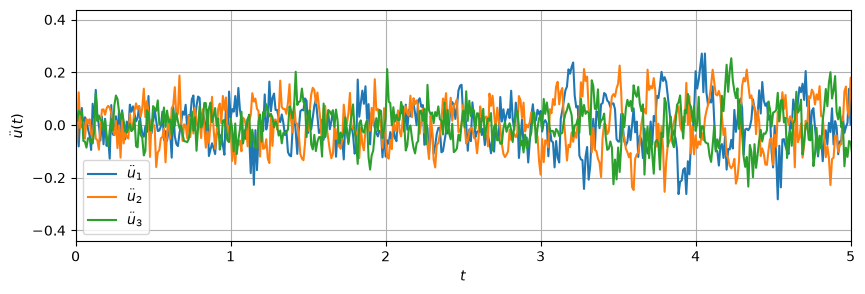

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import stats as sps

import sys
sys.path.append('./../modules')
from time_integration import * # Import all functions in the module time_integration

# Structural properties
m = 1000.0; 
c = 2000.0;
EI = 2.1E11*3.36E-6;
L = 4.0;
k = 2*12*EI/L**3;
M = np.diag([1, 1, 1])*m;
K = np.array([ [2, -1, 0], [-1, 2, -1], [0, -1, 1]])*k
C = np.diag([1, 0.5, 0])*c;

dt=0.01 # Time step
T=600 # Total time
t = np.arange(0,T,dt) # Time vector

rng=np.random.default_rng(9)
f=rng.normal(0,50, size=(3,len(t))) # White noise loading

u0=np.zeros((3,1)) # Initial displacement
udot0=np.zeros((3,1)) # Initial velocity

# Newmark time integration
u, udot, u2dot = linear_newmark_krenk(M,C,K,f,u0,udot0,dt)

# Plot accel
plt.figure(figsize=(10,3))   
plt.plot(t,u2dot[0,:],'-',label='$\ddot{u}_1$')  
plt.plot(t,u2dot[1,:],'-',label='$\ddot{u}_2$')    
plt.plot(t,u2dot[2,:],'-',label='$\ddot{u}_3$')    
plt.xlabel('$t$')
plt.ylabel('$\ddot{u}(t)$');
plt.xlim(0,5)
plt.grid()
plt.legend()


We now assume that the acceleration time series are measured. We estimate their cross-spectral density matrix using Welch's method, as in Example 9.1. The matrix uses $S_{ij}=E[Y_i\overline{Y_j}]$, so the arguments to `csd` are reversed. The frequency axis is in Hz and the spectral densities are per Hz.

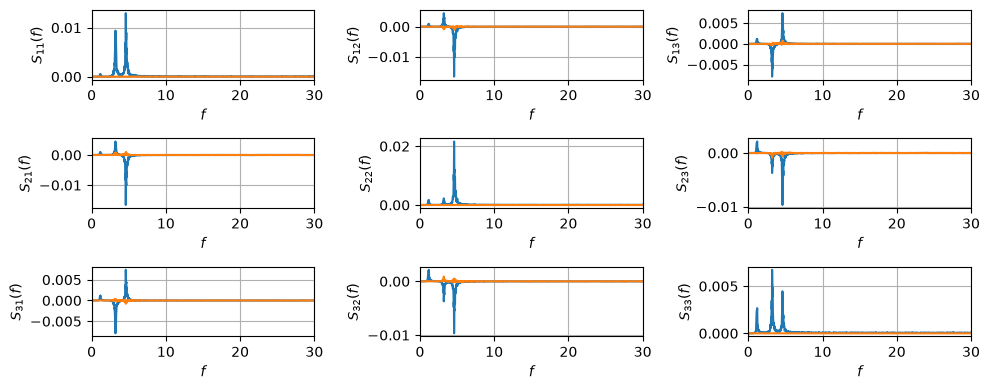

In [2]:
from scipy.signal import welch, csd
import scipy

Ndivisions=10 # Number of divisions of the time series
Nwindow=int(np.ceil(len(t)/Ndivisions)) # Length of window

Nfft_pow2 = int(2**np.ceil(np.log2(Nwindow))) # Next power of 2

# Spectral matrix
S_welch=np.zeros((3,3,np.int32(Nfft_pow2/2+1)),dtype=np.complex128)

# Fill spectral matrix by taking the cross spectral density between each of the 3 time series
for k1 in range(3):
    for k2 in range(3):
            f_welch, S_tmp=scipy.signal.csd(u2dot[k2,:],u2dot[k1,:], fs=1/dt, window='hann', nperseg=Nwindow, noverlap=None, nfft=Nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=-1, average='mean')
            
            S_welch[k1,k2,:]=S_tmp # Spectrum
            
# Plot spectrum
fig, axs = plt.subplots(3,3,figsize=(10,4))    
for k1 in range(3):
    for k2 in range(3):
        ax = axs[k1,k2]
        ax.plot(f_welch,np.real(S_welch[k1,k2,:]))
        ax.plot(f_welch,np.imag(S_welch[k1,k2,:]))
        ax.set_ylabel(('$S_{' + str(k1+1) + str(k2+1) + '}(f)$'))
        ax.set_xlabel('$f$')
        ax.grid(True)
        #ax.set_yscale('log')
        ax.set_xlim(0,30)
plt.tight_layout()


## Frequency domain decomposition (FDD)

This method is based on the singular value decomposition (SVD) of the cross-spectral density matrix. 

The SVD is widely used in linear algebra, and factorizes the matrix $\mathbf{M}$ on the form $\mathbf{M}=\mathbf{U} \mathbf{\Sigma} \mathbf{V}^\text{H}$, where ${(~)}^\text{H}$ denotes the Hermitian transpose (transpose + complex conjugate).  $\mathbf{\Sigma}=\text{diag}(\sigma_1,\sigma_2,\sigma_3,\dots)$ is a diagonal matrix with values called the singular values $\sigma_i$ (usually in descending order). The columns of $\mathbf{U}=[\mathbf{u}_1,\mathbf{u}_2,\mathbf{u}_3,\dots]$ are called the left singular vectors $\mathbf{u}_i$. The singular values $\sigma_i$ are always real, but the singular vectors $\mathbf{u}_i$ could be complex if $\mathbf{M}$ is complex.

$$
\begin{bmatrix}
M_{11} & M_{12} & \dots & M_{1n} \\
M_{21} & M_{22} & \dots & M_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
M_{n1} & M_{n2} & \dots & M_{nn}
\end{bmatrix}
=
\begin{bmatrix}
\vdots  & \vdots & \vdots & \vdots \\
\uparrow  & \uparrow & \vdots & \uparrow \\
\mathbf{u}_{1} & \mathbf{u}_2 & \dots & \mathbf{u}_{n} \\
\downarrow  & \downarrow & \vdots & \downarrow \\
\vdots & \vdots & \vdots & \vdots \\
\end{bmatrix}
~
\begin{bmatrix}
\sigma_{11} &0 & \dots & 0 \\
0 & \sigma_{22} & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & \sigma_{nn}
\end{bmatrix}
~
\begin{bmatrix}
\vdots  & \vdots & \vdots & \vdots \\
\uparrow  & \uparrow & \vdots & \uparrow \\
\mathbf{v}_{1} & \mathbf{v}_2 & \dots & \mathbf{v}_{n} \\
\downarrow  & \downarrow & \vdots & \downarrow \\
\vdots & \vdots & \vdots & \vdots \\
\end{bmatrix}
^\text{H}
$$

The SVD can also be expressed as the sum $\mathbf{M}=\sum_{i=1}^{N} \mathbf{u}_i \sigma_i \mathbf{v}_i^\text{H}$. In simple terms, $\mathbf{M}$ is constructed from many singular vectors, and each singular value describes the importance of the corresponding singular vector (bigger value=more important contribution to "building" the total matrix $\mathbf{M}$).

Now let us consider how the SVD can be used in dynamics. The physical response can be expressed as the sum of contributions from all the modes $ \mathbf{x}(t)= \mathbf{\Phi} \mathbf{\eta}(t)$. This means that the spectrum of the response can be expressed as $ \mathbf{S}_x(\omega)= \mathbf{\Phi}\mathbf{S}_{\eta}(\omega) \mathbf{\Phi}^\text{H} $. When we compare this to the SVD, some similarity can be recognized .

Consider one specific frequency $\omega=\omega_s$. If this is a natural frequency of the structure, only one mode will dominate the total response at that frequency due to resonance (dynamic magnification). This implies that the spectral matrix can be approximated by only considering the first singular vector: $ \mathbf{S}_x(\omega_s) \approx \mathbf{u}_1 \sigma_1 \mathbf{v}_1^\text{H}$. The estimate of the mode shape is then $\mathbf{\phi}_s=\mathbf{u}_1$. Ideally, $\mathbf{\phi}_s$ should be real (or close to real). Due to noise and estimation uncertainty, however, $\mathbf{\phi}_s$ will also have an imaginary part. For approximately real modes, we first rotate the arbitrary complex phase so that the largest component is real and positive, and then consider the real part. The shear frame has non-proportional damping, so its true modes may retain a small imaginary component.



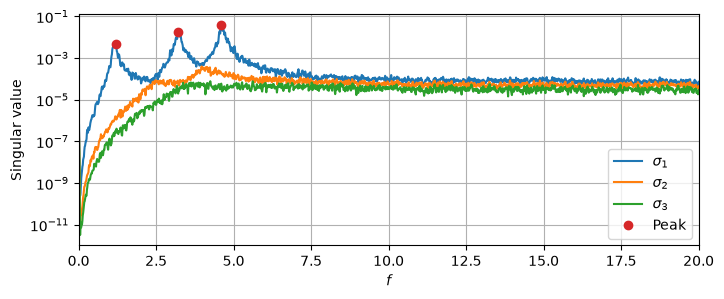

In [3]:
# Frequency domain decomposition
import scipy

# Zero matrices for singular value and singular vector
sigma1=np.zeros(len(f_welch))
sigma2=np.zeros(len(f_welch))
sigma3=np.zeros(len(f_welch))
u1=np.zeros((3,len(f_welch)),dtype=np.complex128)

# Loop over all frequencies 
for k in np.arange(len(f_welch)):

    u,sigma,v=np.linalg.svd(S_welch[:,:,k]) # SVD of slice of spectral matrix
    
    sigma1[k]=sigma[0] # Save first singular value
    u1[:,k]=u[:,0] # Save first singular vector
    sigma2[k]=sigma[1] # Save second singular value
    sigma3[k]=sigma[2] # Save third singular value
    
# Find index of peaks in singular spectrum
peaks_index,_ = scipy.signal.find_peaks(sigma1, distance=50, rel_height=0.5) 

# Pick 3 largest peaks
peaks_index_top3 = np.sort(peaks_index[np.argpartition(sigma1[peaks_index], -3)[-3:]])

# Plot singular value spectrum
plt.figure(figsize=(8,3))
plt.plot(f_welch,sigma1,'-',label='$\sigma_1$')
plt.plot(f_welch,sigma2,'-',label='$\sigma_2$')
plt.plot(f_welch,sigma3,'-',label='$\sigma_3$')
plt.plot(f_welch[peaks_index_top3],sigma1[peaks_index_top3],'o',label = 'Peak')    
plt.xlabel('$f$');
plt.ylabel('Singular value')
plt.yscale('log')
plt.xlim(0,20)
plt.grid()
plt.legend()   


We see that the peaks from the 3 modes are very visible and easy to pick out. They obviously match the same frequencies as the plot of the spectrum. At the natural frequencies, we see that the first singular value is much greater (10000x or 100x) than the next singular value. This shows that one mode is dominating the response at that frequency.

Next, let us plot the modes. The mode shapes are the singular vectors corresponding to the peaks.

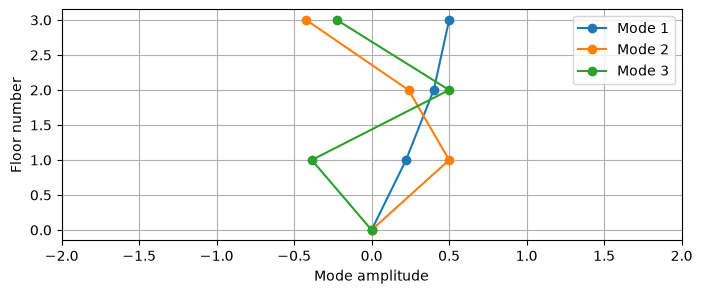

In [4]:
# Plot mode shapes

plt.figure(figsize=(8,3))

phi_all=[None]*3

for k in range(3):
    
    phi=u1[:,peaks_index_top3[k]] # Pick singular vector corresponding to peak
    phi=phi*np.exp(-1j*np.angle(phi[np.argmax(np.abs(phi))])) # Align phase
    phi=np.real(phi) # Take real part only
    phi=phi/np.max(np.abs(phi)) # Normalize max to 1 (mode scaling)
    phi=np.hstack((0,phi)) # Add zero value at base floor of building
    
    plt.plot(phi*0.5,np.arange(4),'-o',label = 'Mode '+ str(k+1))    # Plot this mode 
    
    phi_all[k]=phi

plt.xlabel('Mode amplitude')
plt.ylabel('Floor number')
plt.xlim(-2,2)
plt.grid()
plt.legend()

We observe that the identified modes look reasonable: in mode 1, the entire building is swaying to one side. In mode 2, the first and third floor swing to opposite sides. We can try to animate the modes.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Use this line for inline animations in Jupyter notebook
# If you want interactive animations, use %matplotlib notebook instead
%matplotlib inline  

idx_plot=1

mode_plot=phi_all[0]

lam_plot=1j*1

mode_plot=mode_plot/np.max(np.abs(mode_plot))

# Create a figure and axis
fig, ax = plt.subplots(figsize=(6, 3))

# Plot setup
ax.set_ylabel('Floor')
ax.set_xlabel('Modal deflection')
ax.grid(True)
ax.set_xlim(-3, 3)  # X-limits based on expected deflection
ax.set_ylim(0, 3)   # Y-limits based on number of floors (3 floors in this case)
line_objects = [ax.plot([], [], marker='o')[0]]

# Number of cycles
n_cyc=5

# Animation function
def animate(frame):
    t = frame  # Time step, controls how fast it swings
    # Extract real and imaginary parts
    data_plot = np.real(mode_plot* np.exp(lam_plot*t))  # Multiply by e^(lambda*t) to simulate time-varying
    line_objects[0].set_data(data_plot, [0, 1, 2, 3])  # Update the plot for each mode
    return line_objects

# Create the animation
ani = FuncAnimation(fig, animate, frames=np.linspace(0, 2*np.pi/abs(lam_plot)*n_cyc,200), interval=200, blit=True)

# Close the static figure to prevent double output
plt.close(fig)

# Display the animation in the notebook
HTML(ani.to_jshtml())

Once 
 
 Loop 
 
 Reflect